# Detección de daño en puentes con *compressed sensing* de datos de teléfonos en vehículos

**Referencia:** Talebi-Kalaleh, M. y Mei, Q. (2024). *Damage Detection in Bridge Structures through Compressed Sensing of Crowdsourced Smartphone Data*. Structural Control and Health Monitoring, 2024, 5436675. https://doi.org/10.1155/2024/5436675

**PDF:** [2024-talebi-kalaleh-compressed-sensing-damage-detection.pdf](2024-talebi-kalaleh-compressed-sensing-damage-detection.pdf)

**El artículo en una frase:** los teléfonos de los vehículos que cruzan un puente guardan y envían **solo una fracción aleatoria** de las muestras de aceleración; en el servidor se reconstruye la señal completa con *compressed sensing* y, a partir de muchas señales, se detecta el daño comparando distribuciones de características (MFCC + PCA) con la distancia de Wasserstein.

> **Sobre los ejemplos de código.** Los ejemplos reproducen el estudio numérico del artículo con una **simulación propia simplificada** (modelo modal del puente y vehículo de un grado de libertad). Sus números no son los del artículo. Los valores **reportados por el artículo** se indican siempre de forma explícita; los que se leen de sus gráficas son aproximados.

<a id="indice"></a>
## Índice

- [Glosario](#glosario)
1. [Problema](#problema)
2. [Propósito](#proposito)
3. [Conceptos clave](#conceptos)
    - 3.1 [*Compressed sensing* (muestreo compresivo)](#c-cs)
    - 3.2 [MFCC (coeficientes cepstrales en frecuencia Mel)](#c-mfcc)
    - 3.3 [PCA (análisis de componentes principales)](#c-pca)
    - 3.4 [Distancia de Wasserstein](#c-wass)
4. [Metodología](#metodologia)
    - 4.1 [Compresión y reconstrucción de la señal](#m-cs)
    - 4.2 [Extracción de características con MFCC](#m-mfcc)
    - 4.3 [Reducción de dimensión con PCA](#m-pca)
    - 4.4 [Distancia de Wasserstein entre distribuciones](#m-wass)
    - 4.5 [Índice de daño](#m-di)
5. [Procedimiento](#procedimiento)
    - 5.1 [Puente numérico y escenarios de daño](#p-puente)
    - 5.2 [Vehículos simulados](#p-vehiculos)
    - 5.3 [Interacción vehículo–puente y señales](#p-vbi)
    - 5.4 [Compresión de las señales](#p-cs)
    - 5.5 [Características, PCA y repeticiones](#p-runs)
    - 5.6 [Experimento de laboratorio](#p-lab)
    - 5.7 [Caso de campo: puente Golden Gate](#p-gg)
6. [Resultados](#resultados)
    - 6.1 [Reconstrucción de señales](#r-recon)
    - 6.2 [Índice de daño en el modelo numérico](#r-num)
    - 6.3 [Índice de daño en el laboratorio](#r-lab)
    - 6.4 [Falsas alarmas en el Golden Gate](#r-gg)
7. [Conclusiones y limitaciones](#conclusiones)

<a id="glosario"></a>
## Glosario

Términos y siglas que aparecen en este notebook, agrupados por tema. Los marcados con → tienen una ficha completa en [Conceptos clave](#conceptos).

**Monitoreo de puentes**

- **SHM** (*Structural Health Monitoring*, monitoreo de la salud estructural): seguimiento del estado de una estructura con mediciones, para detectar daño a tiempo.
- **Monitoreo indirecto o *drive-by*:** medir la vibración del puente con sensores en un vehículo que lo cruza, en lugar de sensores en el puente.
- ***Crowdsensing*** (o *crowdsourcing* de datos): recolectar datos con los dispositivos de mucha gente, p. ej. teléfonos en autos comunes.
- **IoT** (*Internet of Things*, internet de las cosas): dispositivos con sensores conectados a internet (teléfonos, autos).
- **Línea base** (*baseline*): datos del puente sano que sirven de referencia.
- **Conjunto de validación:** otra parte de los datos sanos, usada para saber cuánto varía el índice cuando no hay daño.
- **Caso desconocido:** datos nuevos cuya condición (sano o dañado) se quiere determinar.
- **Verdadero negativo / falso positivo:** declarar sano un puente sano / declarar dañado un puente sano (falsa alarma).
- **DC** (*Damage Case*): escenario de daño. DC0 es el puente sano.
- **DI** (*Damage Index*, índice de daño): distancia de Wasserstein del caso desconocido normalizada por la del caso de validación, Ec. (13).

**Dinámica estructural**

- **Frecuencia natural** ($f_n$, en Hz): frecuencia a la que la estructura vibra libremente en su modo $n$; baja si el daño reduce la rigidez. **Frecuencia angular** ($\omega = 2\pi f$, en rad/s): la misma magnitud expresada en radianes por segundo.
- **Rigidez a flexión** ($EI$): módulo de elasticidad por inercia; resistencia de la viga a flexionarse.
- **Viga simplemente apoyada / empotrada:** apoyos que permiten el giro / que lo impiden.
- **Condición de borde:** forma en que la estructura está apoyada (articulada, empotrada).
- **Elementos finitos (FE):** método numérico que divide la estructura en elementos pequeños. **Abaqus** es el programa comercial que usan los autores.
- **Superposición modal:** escribir la respuesta como suma de las contribuciones de unos pocos modos.
- **VBI** (*Vehicle–Bridge Interaction*): acoplamiento dinámico entre vehículo y puente.
- **Sistema masa–resorte:** modelo de vehículo de un eje: una masa $m$ sobre un resorte $k$.
- **Relación de masas vehículo–puente:** masa del vehículo dividida por la masa del puente.
- **Rugosidad del pavimento:** irregularidades de la superficie que también excitan al vehículo.
- **Prueba de impacto:** golpear la estructura y medir su respuesta para obtener sus frecuencias.

**Procesamiento de señales**

- **Frecuencia de muestreo** ($f_s$): muestras por segundo.
- **Teorema de Nyquist–Shannon:** para capturar sin pérdida una señal con frecuencias hasta $f_{\max}$ hay que muestrear al menos a $2 f_{\max}$ (la **frecuencia de Nyquist**).
- **Submuestreo** (*downsampling*): conservar menos muestras de una señal ya registrada.
- ***Compressed sensing* (CS)** → [3.1](#c-cs): adquirir pocas muestras aleatorias y reconstruir la señal completa aprovechando que es dispersa.
- **Señal dispersa** (*sparse*): señal que, escrita en una base adecuada, tiene casi todos sus coeficientes iguales o cercanos a cero.
- **Nivel de compresión (CL):** porcentaje de muestras que se **descartan**. CL = 80 % significa que solo se conserva el 20 % de las muestras.
- **Matriz de medición** ($\boldsymbol{\Psi}$): matriz que indica qué muestras se conservan.
- **DCT** (*Discrete Cosine Transform*, transformada discreta del coseno): expresa una señal como suma de cosenos; concentra la energía en pocos coeficientes. **I-DCT** es su inversa.
- **DFT / FFT:** transformada discreta de Fourier y su algoritmo rápido; dan el espectro de la señal.
- **Norma L1** ($\lVert \mathbf{X} \rVert_1$): suma de los valores absolutos; minimizarla favorece soluciones con muchos ceros. **Norma L2** ($\lVert \cdot \rVert_2$): raíz de la suma de cuadrados.
- **LASSO:** problema de mínimos cuadrados con penalización L1, Ec. (4).
- **ISTA / FISTA:** algoritmos iterativos para resolver LASSO con umbralización suave (*soft thresholding*).
- **$R^2$** (coeficiente de determinación): qué fracción de la variación de la señal original explica la reconstruida; 1 es perfecto.
- **Espectro de potencia:** $|X(f)|^2$, energía de la señal en cada frecuencia.
- **Escala Mel, banco de filtros, cepstrum:** ver la ficha de MFCC.
- **MFCC** (*Mel-Frequency Cepstral Coefficients*) → [3.2](#c-mfcc): resumen compacto de la forma del espectro de una señal.

**Estadística**

- **PCA** (*Principal Component Analysis*) → [3.3](#c-pca): técnica que resume muchas variables correlacionadas en pocas componentes.
- **Componente principal:** combinación lineal de las variables originales que recoge la mayor varianza posible.
- **Varianza explicada:** fracción de la varianza total que recoge cada componente.
- **SVD** (*Singular Value Decomposition*): descomposición de una matriz que se usa para calcular la PCA.
- **PDF** (*Probability Density Function*, función de densidad de probabilidad): describe cómo se distribuyen los valores de una variable aleatoria.
- **Distancia de Wasserstein** (o *Earth Mover's Distance*) → [3.4](#c-wass): costo mínimo de transformar una distribución en otra.
- **Divergencia de Kullback–Leibler (KL):** otra medida de diferencia entre distribuciones; no es simétrica y puede ser infinita.
- **Matriz de covarianza** ($\boldsymbol{\Sigma}$): varianzas en la diagonal y covarianzas fuera; describe la dispersión de los datos.
- **Traza** ($\operatorname{tr}$): suma de la diagonal de una matriz. **Raíz cuadrada de una matriz** ($\boldsymbol{\Sigma}^{1/2}$): matriz que multiplicada por sí misma da $\boldsymbol{\Sigma}$.
- **Umbral:** valor del índice de daño a partir del cual se declara daño.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown
from scipy.fft import idct
from scipy.linalg import eigh, sqrtm
from scipy.signal import resample_poly
from scipy.stats import norm

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


# Display a table with its caption above it
def show_table(df, number, caption, precision=2, hide_index=False):
    display(Markdown(f"**Tabla {number}.** {caption}"))
    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)


# Display a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

<a id="problema"></a>
## 1. Problema

- **Puentes deteriorados.** Cerca del 9 % de los puentes de EE. UU. son estructuralmente deficientes (FHWA) y cerca del 40 % de los de Canadá están en estado "regular", "malo" o "muy malo" (Canadian Infrastructure Report Card, 2019).
- **El SHM con sensores fijos es caro.** Instalar sensores cuesta, toma tiempo y puede obligar a cerrar el puente. Por eso la mayoría de los puentes cortos y medianos no se monitorea.
- **El crowdsensing es una alternativa barata.** Los teléfonos de los vehículos que cruzan el puente registran su aceleración, y con muchos cruces se puede detectar daño (Mei y Gül, 2019; Matarazzo et al., 2018).
- **Vacío que ataca el artículo.** Registrar y enviar aceleraciones a alta frecuencia de muestreo **gasta batería y datos móviles** de los participantes, lo que desalienta la participación del público. Se necesita reducir la cantidad de datos que cada teléfono guarda y envía **sin perder** la información útil para detectar daño.

<a id="proposito"></a>
## 2. Propósito

**Objetivo:** proponer un marco de monitoreo indirecto por crowdsensing que use **compressed sensing** para reducir la cantidad de datos que se recolectan y transmiten, manteniendo la capacidad de detectar daño.

**Aportes:**

1. Integrar *compressed sensing* en el monitoreo por crowdsensing: cada teléfono guarda solo muestras aleatorias y la señal completa se reconstruye en el servidor.
2. Un índice de daño basado en la **distancia de Wasserstein** entre las distribuciones de características (MFCC reducidos con PCA) del puente sano y del puente en estado desconocido.
3. Validación en tres niveles: modelo numérico, puente de laboratorio (con acelerómetros y un teléfono) y datos reales de 102 cruces del **puente Golden Gate**.

**Pregunta central:** ¿cuántas muestras se pueden descartar (nivel de compresión) sin perder la capacidad de detectar el daño y su severidad?

<a id="conceptos"></a>
## 3. Conceptos clave

El artículo se apoya en cuatro ideas. Aquí se explica qué es cada una, para qué sirve, por qué se eligió y cuándo conviene o no usarla. Cómo las aplica el artículo (fórmulas y código) está en la [Metodología](#metodologia).

<a id="c-cs"></a>
### 3.1 *Compressed sensing* (muestreo compresivo)

**Qué es.** Una teoría de adquisición de señales (Candès, Romberg y Tao, 2006; Donoho, 2006) que permite **reconstruir una señal a partir de muchas menos muestras** de las que exige el teorema de Nyquist–Shannon, siempre que la señal sea **dispersa** en alguna base. Se apoya en tres ideas:

- **Dispersidad:** muchas señales reales, escritas en una base adecuada (Fourier, coseno, wavelets), tienen solo unos pocos coeficientes importantes. Una vibración dominada por pocos modos es dispersa en frecuencia.
- **Muestreo aleatorio:** las muestras se toman en instantes al azar, no a intervalos regulares. Así cada muestra "ve" un poco de todos los coeficientes y no se pierde ninguno en particular.
- **Reconstrucción por optimización L1:** entre todas las señales que coinciden con las muestras tomadas, se elige la que tiene menos coeficientes distintos de cero. Minimizar la norma L1 es la forma práctica de lograrlo.

**Para qué sirve.** Para medir o transmitir menos datos cuando adquirir, guardar o enviar cada muestra es caro (resonancia magnética, cámaras de un píxel, redes de sensores inalámbricos).

**Por qué se usó en este artículo.** En crowdsensing, cada participante paga con su batería y su plan de datos. Si el teléfono guarda y envía solo el 20–50 % de las muestras, la participación es más barata. Las aceleraciones de un vehículo sobre un puente están dominadas por unas pocas frecuencias (vehículo y primeros modos del puente), así que son dispersas en la base del coseno.

**Cuándo conviene usarlo.**

- Señales dispersas en una base conocida.
- Cuando el costo está en **adquirir o transmitir** las muestras, y el receptor tiene capacidad de cálculo para reconstruir.
- Cuando el sensor puede muestrear en instantes aleatorios.

**Cuándo no conviene.**

- Señales poco dispersas: ruido de banda ancha, impactos, transitorios bruscos.
- Cuando se necesita una reconstrucción exacta de cada muestra.
- Cuando el sensor ya muestrea de forma uniforme y el ahorro solo está en la transmisión: en ese caso, comprimir después de medir (o enviar directamente las características) suele ser más simple.
- Cuando la reconstrucción es demasiado costosa para el receptor (miles de señales que optimizar).

**Alternativas.** Compresión convencional después de medir (guardar solo los coeficientes DCT o wavelet más grandes, como JPEG o MP3); submuestreo uniforme con filtro antialias si la banda útil es más baja; calcular las características (p. ej. los MFCC) **en el propio teléfono** y enviar solo esos números.

<a id="c-mfcc"></a>
### 3.2 MFCC (coeficientes cepstrales en frecuencia Mel)

**Qué es.** MFCC son las siglas de *Mel-Frequency Cepstral Coefficients*. Son unos pocos números que describen la **forma general del espectro** (su envolvente) de una señal. Se crearon para el reconocimiento de voz (Davis y Mermelstein, 1980). El nombre resume cómo se calculan: el espectro se mide en la **escala Mel**, que da más resolución a las frecuencias bajas, y se le aplica un análisis **cepstral** (*cepstrum*, anagrama de *spectrum*: el "espectro del logaritmo del espectro"), que separa la forma general del espectro de sus detalles finos. Se conservan los primeros **coeficientes**.

**Para qué sirve.** Para convertir cada señal, sea de la duración que sea, en un vector corto de números comparables entre sí, listo para estadística o aprendizaje automático.

**Por qué se usó en este artículo.** Los autores lo introdujeron en el monitoreo de puentes en 2019 (Mei y Gül). Según el artículo, el análisis cepstral usa información de todo el rango de frecuencias y no solo de los picos, y la escala Mel da más peso a las frecuencias bajas, donde están los modos importantes del puente.

**Cuándo conviene usarlo.** Muchas señales cortas y ruidosas; cuando interesa detectar cambios más que medir parámetros físicos.

**Cuándo no conviene.** Cuando se necesitan frecuencias, formas modales o amortiguamientos (los MFCC no tienen interpretación física directa); cuando la información útil está en frecuencias altas; cuando otros factores (velocidad, tipo de vehículo, temperatura) cambian el espectro tanto como el daño.

**Alternativas.** Picos del espectro; identificación modal; transformadas tiempo–frecuencia (wavelets).

> En el notebook de [Zeng et al. (2025)](../2025-zeng-mishm-multibridge-drive-by-shm/2025-zeng-mishm-multibridge-drive-by-shm.ipynb#c-mfcc) hay una explicación más detallada, con el cálculo paso a paso y sus gráficas.

<a id="c-pca"></a>
### 3.3 PCA (análisis de componentes principales)

**Qué es.** *Principal Component Analysis* (Pearson, 1901; Hotelling, 1933) es una técnica que busca las **direcciones en las que los datos varían más** y los reescribe en esas direcciones (las componentes principales). Las componentes no están correlacionadas entre sí y están ordenadas de mayor a menor varianza, así que las primeras resumen casi toda la información.

**Para qué sirve.** Para reducir muchas variables correlacionadas a unas pocas, eliminar redundancia y facilitar la visualización y la estadística.

**Por qué se usó en este artículo.** Los 20–30 MFCC de cada señal están correlacionados. La PCA los reduce a unas pocas componentes antes de comparar distribuciones, lo que hace más estable la distancia de Wasserstein. Los autores además sostienen que la PCA ayuda a filtrar el efecto de la velocidad y de las propiedades de los vehículos.

**Cuándo conviene usarla.**

- Muchas variables con relaciones aproximadamente lineales.
- Cuando la información útil está en las direcciones de mayor varianza.

**Cuándo no conviene.**

- Relaciones no lineales entre variables.
- Cuando la señal de interés (el daño) es pequeña y queda en componentes de **poca** varianza: la PCA podría descartarla, porque busca varianza, no daño.
- Variables con escalas muy distintas sin estandarizar.

**Alternativas.** Kernel PCA o *autoencoders* (relaciones no lineales); análisis discriminante (si hay etiquetas de daño); selección directa de variables.

<a id="c-wass"></a>
### 3.4 Distancia de Wasserstein

**Qué es.** Una medida de qué tan distintas son dos distribuciones de probabilidad, definida como el **costo mínimo de transformar una en la otra**. Si cada distribución se imagina como un montón de tierra, es el trabajo mínimo (cantidad de tierra × distancia recorrida) para convertir un montón en el otro; por eso también se llama *Earth Mover's Distance*. Viene de la teoría del transporte óptimo (Monge, 1781; Kantorovich, 1942).

- Es **simétrica** y cumple la desigualdad triangular: es una distancia en sentido estricto.
- Es finita aunque las distribuciones no se superpongan, y crece de forma suave al separarlas.

**Para qué sirve.** Para comparar distribuciones (de datos, de imágenes, de características) teniendo en cuenta **cuánto** se desplazaron, no solo si coinciden.

**Por qué se usó en este artículo.** El daño desplaza la nube de características de los vehículos. La distancia de Wasserstein mide ese desplazamiento entre la línea base y el caso desconocido, es simétrica y no explota cuando las nubes apenas se superponen. Esa es una ventaja frente a la divergencia KL, que no es simétrica y puede ser infinita.

**Cuándo conviene usarla.**

- Para comparar distribuciones que pueden estar desplazadas o tener formas distintas.
- Cuando se quiere una medida con unidades de las variables (es una "distancia" real).

**Cuándo no conviene.**

- En muchas dimensiones con pocas muestras: su estimación a partir de muestras converge lento.
- Cuando el costo de cálculo importa: en general requiere resolver un problema de optimización. Solo en casos especiales (una dimensión, o distribuciones normales) tiene fórmula cerrada.
- Cuando las variables tienen escalas distintas sin estandarizar: la distancia queda dominada por las de mayor escala.

**Alternativas.** Divergencia KL; divergencia de Jensen–Shannon; distancia de Mahalanobis; MMD (*Maximum Mean Discrepancy*); pruebas estadísticas como la $T^2$ de Hotelling.

<a id="metodologia"></a>
## 4. Metodología

El marco tiene tres etapas (Fig. 1 del artículo):

1. **Compressed sensing:** cada teléfono guarda solo muestras aleatorias de la aceleración y las envía; el servidor reconstruye la señal completa.
2. **Extracción de características:** cada señal reconstruida se resume en un vector de MFCC; con todas las señales se arma la matriz de características $\mathbf{U}$ y se reduce con PCA.
3. **Detección de anomalías:** se compara la distribución de las características del caso desconocido con la de la línea base usando la distancia de Wasserstein, y se normaliza con la del caso de validación para obtener el índice de daño (DI).

La Figura 1 resume el flujo y la Tabla 1 reúne la notación.

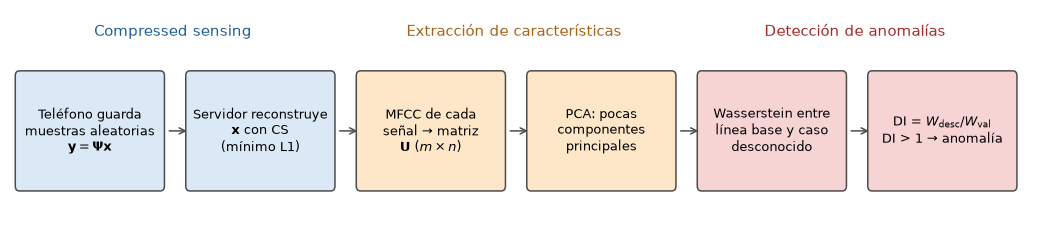

**Figura 1.** Flujo del marco propuesto (esquema propio basado en la Fig. 1 del artículo).

In [2]:
# Flowchart of the framework (own schematic)
steps = [
    ("Teléfono guarda\nmuestras aleatorias\n$\\mathbf{y} = \\boldsymbol{\\Psi}\\mathbf{x}$", "#dbe9f6"),
    ("Servidor reconstruye\n$\\mathbf{x}$ con CS\n(mínimo L1)", "#dbe9f6"),
    ("MFCC de cada\nseñal → matriz\n$\\mathbf{U}$ ($m \\times n$)", "#fde7c8"),
    ("PCA: pocas\ncomponentes\nprincipales", "#fde7c8"),
    ("Wasserstein entre\nlínea base y caso\ndesconocido", "#f7d4d4"),
    ("DI = $W_{\\mathrm{desc}}/W_{\\mathrm{val}}$\nDI > 1 → anomalía", "#f7d4d4"),
]
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.set_xlim(0, len(steps) * 2.0)
ax.set_ylim(0, 2.2)
ax.axis("off")
for k, (label, color) in enumerate(steps):
    x0 = 0.1 + k * 2.0
    ax.add_patch(FancyBboxPatch((x0, 0.45), 1.65, 1.1, boxstyle="round,pad=0.05", fc=color, ec="0.3"))
    ax.text(x0 + 0.825, 1.0, label, ha="center", va="center", fontsize=8.5)
    if k < len(steps) - 1:
        ax.annotate("", xy=(x0 + 2.0, 1.0), xytext=(x0 + 1.72, 1.0), arrowprops=dict(arrowstyle="->", color="0.3"))
for x_mid, text, color in [(1.9, "Compressed sensing", "#1f5f99"), (5.9, "Extracción de características", "#a5641a"),
                           (9.9, "Detección de anomalías", "#a52a2a")]:
    ax.text(x_mid, 1.95, text, ha="center", fontsize=10, color=color)
show_figure(fig, 1, "Flujo del marco propuesto (esquema propio basado en la Fig. 1 del artículo).")

**Tabla 1.** Notación principal.

| Símbolo | Significado |
|---|---|
| $\mathbf{x}$ ($N \times 1$) | Señal de aceleración original, muestreada a la frecuencia de Nyquist |
| $\mathbf{X}$ ($N \times 1$) | Coeficientes DCT de $\mathbf{x}$ (su representación en la base del coseno) |
| $\mathbf{A}_N^{-1}$ ($N \times N$) | Matriz de la DCT inversa (I-DCT) |
| $\boldsymbol{\Psi}$ ($M \times N$) | Matriz de medición: selecciona $M \ll N$ muestras al azar |
| $\mathbf{y}$ ($M \times 1$) | Medición comprimida: las muestras que el teléfono guarda y envía |
| CL | Nivel de compresión: $1 - M/N$ |
| $c$ | Parámetro de regularización de la reconstrucción |
| $\mathbf{U}$ ($m \times n$) | Matriz de características: $m$ señales (vehículos) × $n$ MFCC |
| $P$, $Q_k$ | Distribuciones de las características de la línea base y del caso $k$ |
| $W_p(P, Q_k)$ | Distancia de Wasserstein de orden $p$ |
| DI | Índice de daño |

<a id="m-cs"></a>
### 4.1 Compresión y reconstrucción de la señal

Qué es el *compressed sensing* y por qué se eligió está en la [ficha 3.1](#c-cs). Aquí se siguen las ecuaciones del artículo (Sección 2.1).

**Paso 1. La señal es dispersa en la base del coseno.** La señal $\mathbf{x}$ se escribe a partir de sus coeficientes DCT (Ec. 1 del artículo):

$$\mathbf{x} = \mathbf{A}_N^{-1}\,\mathbf{X} \tag{1}$$

donde $\mathbf{A}_N^{-1}$ es la DCT inversa de tipo II ortonormal (Ec. 2 del artículo). Elemento a elemento:

$$x_t = \sum_{k=0}^{N-1} \alpha_k\, X_k \cos\!\left(\frac{\pi\,(2t+1)\,k}{2N}\right), \qquad \alpha_0 = \sqrt{1/N},\ \ \alpha_{k>0} = \sqrt{2/N} \tag{2}$$

donde $x_t$ es la muestra $t$ de la señal, $X_k$ el coeficiente del coseno $k$ y $\alpha_k$ el factor que hace ortonormal la transformada. La DCT concentra la energía en pocos coeficientes, más que la DFT; por eso los autores la eligen.

**Paso 2. Medición comprimida.** El teléfono guarda solo $M$ de las $N$ muestras, elegidas al azar (Ec. 3 del artículo):

$$\mathbf{y} = \boldsymbol{\Psi}\,\mathbf{x} \tag{3}$$

donde cada fila de $\boldsymbol{\Psi}$ tiene un 1 en la posición de una muestra conservada y ceros en el resto. La matriz se genera antes de medir y la conoce el servidor.

**Paso 3. Reconstrucción.** Se buscan los coeficientes DCT que reproducen las muestras guardadas y que, a la vez, son lo más dispersos posible (Ec. 4 del artículo):

$$\hat{\mathbf{X}} = \arg\min_{\mathbf{X}} \left[\, \lVert \boldsymbol{\Psi}\mathbf{A}_N^{-1}\mathbf{X} - \mathbf{y} \rVert_2^2 + c\,\lVert \mathbf{X} \rVert_1 \right], \qquad \mathbf{x}_{\text{recon}} = \mathbf{A}_N^{-1}\hat{\mathbf{X}} \tag{4}$$

El primer término exige coincidir con las muestras medidas; el segundo ($\lVert\mathbf{X}\rVert_1 = \sum_k |X_k|$) premia tener pocos coeficientes distintos de cero; $c$ equilibra ambos.

**Cómo se resuelve aquí.** El artículo dice que se puede usar "cualquier paquete de optimización". Aquí se usa **FISTA**, que repite una actualización de gradiente seguida de una **umbralización suave**:

$$\mathbf{X} \leftarrow S_c\!\left(\mathbf{X} - \boldsymbol{\Phi}^{T}(\boldsymbol{\Phi}\mathbf{X} - \mathbf{y})\right), \qquad S_c(z) = \operatorname{sign}(z)\,\max(|z| - c,\ 0) \tag{5}$$

donde $\boldsymbol{\Phi} = \boldsymbol{\Psi}\mathbf{A}_N^{-1}$ y $S_c$ lleva a cero los coeficientes pequeños (menores que $c$) y achica los demás. FISTA añade un término de "impulso" que acelera la convergencia. Se toma $c$ igual al 1 % del mayor valor de $|\boldsymbol{\Phi}^T\mathbf{y}|$.

La Figura 2 muestra el proceso con una señal sintética de 3 s a 40 Hz formada por tres frecuencias.

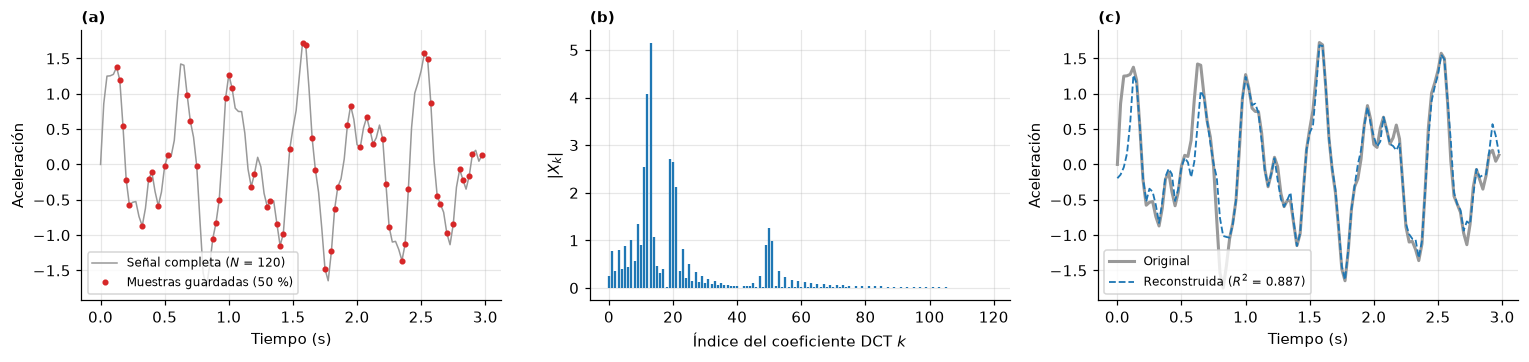

**Figura 2.** Compressed sensing con una señal sintética. (a) Señal y 50 % de muestras aleatorias. (b) Coeficientes DCT: pocos son grandes (la señal es dispersa). (c) Reconstrucción con la Ec. (4) a partir de la mitad de las muestras.

In [3]:
def idct_matrix(n):
    # Orthonormal inverse DCT-II matrix A_N^-1 of Eq. (2): x = A_inv @ X
    return idct(np.eye(n), norm="ortho", axis=0)


def cs_reconstruct(x, cl, rng, c_rel=0.01, n_iter=150):
    # Keep a random (1 - cl) fraction of the samples and rebuild x by solving Eq. (4) with FISTA, Eq. (5)
    n = x.size
    m = max(2, int(round((1 - cl) * n)))
    kept = np.sort(rng.choice(n, m, replace=False))       # rows of the sensing matrix Psi
    y = x[kept]                                            # Eq. (3)
    A_inv = idct_matrix(n)
    Phi = A_inv[kept]                                      # Psi @ A_inv
    c = c_rel * np.abs(Phi.T @ y).max()
    X = np.zeros(n)
    Z = X.copy()
    t_k = 1.0
    for _ in range(n_iter):
        g = Z - Phi.T @ (Phi @ Z - y)                      # gradient step (step size 1: ||Phi|| <= 1)
        X_new = np.sign(g) * np.maximum(np.abs(g) - c, 0)  # soft thresholding
        t_new = (1 + np.sqrt(1 + 4 * t_k**2)) / 2
        Z = X_new + (t_k - 1) / t_new * (X_new - X)        # momentum (FISTA)
        X, t_k = X_new, t_new
    return A_inv @ X, kept


def r_squared(x, x_hat):
    return 1 - np.sum((x - x_hat)**2) / np.sum((x - x.mean())**2)


# Synthetic signal: three frequencies sampled at 40 Hz for 3 s
fs_demo = 40.0
t = np.arange(0, 3, 1 / fs_demo)
demo_rng = np.random.default_rng(SEED)
x_demo = np.sin(2 * np.pi * 2.08 * t) + 0.6 * np.sin(2 * np.pi * 3.3 * t) + 0.25 * np.sin(2 * np.pi * 8.33 * t)
X_demo = idct_matrix(t.size).T @ x_demo                    # forward DCT (inverse of an orthonormal matrix = transpose)
x_rec, kept = cs_reconstruct(x_demo, 0.5, demo_rng)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(t, x_demo, color="0.6", lw=1, label="Señal completa ($N$ = 120)")
axes[0].plot(t[kept], x_demo[kept], "o", ms=3, color="C3", label="Muestras guardadas (50 %)")
axes[0].set(xlabel="Tiempo (s)", ylabel="Aceleración")
axes[1].stem(np.abs(X_demo), markerfmt=" ", basefmt=" ")
axes[1].set(xlabel="Índice del coeficiente DCT $k$", ylabel="$|X_k|$")
axes[2].plot(t, x_demo, color="0.6", lw=2, label="Original")
axes[2].plot(t, x_rec, "--", color="C0", lw=1.2, label=f"Reconstruida ($R^2$ = {r_squared(x_demo, x_rec):.3f})")
axes[2].set(xlabel="Tiempo (s)", ylabel="Aceleración")
for ax, tag in zip(axes, "abc"):
    if tag != "b":
        ax.legend(fontsize=8, loc="lower left")
    ax.text(0.0, 1.03, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout()
show_figure(fig, 2, "Compressed sensing con una señal sintética. (a) Señal y 50 % de muestras aleatorias. (b) Coeficientes DCT: "
                    "pocos son grandes (la señal es dispersa). (c) Reconstrucción con la Ec. (4) a partir de la mitad de las muestras.")

**Interpretación.** Las frecuencias de la señal no coinciden exactamente con los cosenos de la base, así que cada pico se reparte en varios coeficientes vecinos; aun así, la energía se concentra en pocos coeficientes (Figura 2b). Con la mitad de las muestras, tomadas al azar, la reconstrucción recupera bien la señal, con errores sobre todo en los extremos (Figura 2c). Si la señal no fuera dispersa, la reconstrucción fallaría.

<a id="m-mfcc"></a>
### 4.2 Extracción de características con MFCC

Qué son los MFCC y por qué se eligieron está en la [ficha 3.2](#c-mfcc). El cálculo del artículo (Sección 2.2) tiene cinco pasos:

1. Transformada de Fourier de la señal reconstruida → espectro de potencia $|X(k)|^2$.
2. $n$ frecuencias clave igualmente espaciadas en la escala Mel adaptada (Ec. 6 del artículo):

$$m = 5\,\ln\!\left(1 + \frac{f}{5}\right) \qquad\Longleftrightarrow\qquad f = 5\left(e^{m/5} - 1\right) \tag{6}$$

donde $f$ es la frecuencia en Hz y $m$ en la escala Mel.

3. Un filtro triangular de **altura 1** centrado en cada frecuencia clave $f_i$ (Ec. 5 del artículo). A diferencia de Zeng et al. (2025), estos triángulos **no** están normalizados por área:

$$H_i(k) = \begin{cases} \dfrac{k - f_{i-1}}{f_i - f_{i-1}}, & f_{i-1} \le k < f_i \\[1.5ex] \dfrac{f_{i+1} - k}{f_{i+1} - f_i}, & f_i \le k < f_{i+1} \\[1.5ex] 0, & \text{en otro caso} \end{cases} \qquad i = 2, \dots, n-1 \tag{7}$$

4. Logaritmo de la energía de cada filtro (Ec. 7 del artículo):

$$\log E(i) = \log\!\left(\sum_k H_i(k)\,|X(k)|^2\right) \tag{8}$$

5. DCT de las log-energías (Ec. 8 del artículo):

$$\text{MFCC}_j = \sum_{i=2}^{n-1} \log E(i)\,\cos\!\left[\frac{\pi}{n-2}\left(i - \frac{3}{2}\right) j\right] \tag{9}$$

Los MFCC de las $m$ señales forman la matriz de características $\mathbf{U}$ ($m \times n_{\text{MFCC}}$). El artículo usa 20 MFCC en el modelo numérico y 30 en el laboratorio.

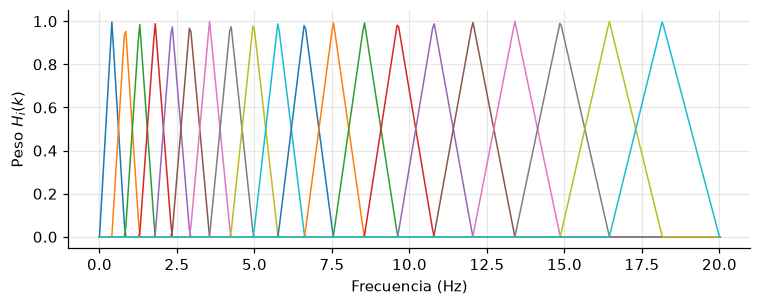

**Figura 3.** Banco de 20 filtros triangulares de altura 1, Ec. (7), en la escala Mel adaptada: estrechos y densos en frecuencias bajas, anchos en las altas.

In [4]:
FS = 40.0          # Nyquist sampling rate used for the numerical model (Hz)
N_KEY = 22         # key frequencies n -> 20 triangular filters -> 20 MFCCs (paper: 20 MFCCs)
N_MFCC = 20
F_MAX = FS / 2
f_grid = np.linspace(0, F_MAX, 401)


def hz_to_mel(f):
    return 5 * np.log(1 + f / 5)


def mel_to_hz(m):
    return 5 * (np.exp(m / 5) - 1)


key_hz = mel_to_hz(np.linspace(hz_to_mel(0), hz_to_mel(F_MAX), N_KEY))   # Eq. (6)
H_mel = np.zeros((N_KEY - 2, f_grid.size))
for i in range(1, N_KEY - 1):                                             # Eq. (7): unit-height triangles
    fl, fc, fr = key_hz[i - 1], key_hz[i], key_hz[i + 1]
    rise = (f_grid >= fl) & (f_grid < fc)
    fall = (f_grid >= fc) & (f_grid < fr)
    H_mel[i - 1, rise] = (f_grid[rise] - fl) / (fc - fl)
    H_mel[i - 1, fall] = (fr - f_grid[fall]) / (fr - fc)
_i = np.arange(2, N_KEY)
_j = np.arange(1, N_MFCC + 1)
DCT_MFCC = np.cos(np.pi / (N_KEY - 2) * np.outer(_j, _i - 1.5))           # Eq. (9)


def mfcc(x, fs=FS, nfft=512):
    power = np.abs(np.fft.rfft(x, nfft))**2                               # step 1
    power_grid = np.interp(f_grid, np.fft.rfftfreq(nfft, 1 / fs), power)
    log_e = np.log(H_mel @ power_grid + 1e-12)                            # Eq. (8)
    return DCT_MFCC @ log_e                                               # Eq. (9)


fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(f_grid, H_mel.T, lw=1)
ax.set(xlabel="Frecuencia (Hz)", ylabel="Peso $H_i(k)$")
show_figure(fig, 3, f"Banco de {N_KEY - 2} filtros triangulares de altura 1, Ec. (7), en la escala Mel adaptada: "
                    "estrechos y densos en frecuencias bajas, anchos en las altas.")

<a id="m-pca"></a>
### 4.3 Reducción de dimensión con PCA

Qué es la PCA y por qué se eligió está en la [ficha 3.3](#c-pca). El artículo no da fórmulas ni el número de componentes. Aquí se usa la forma estándar:

$$\mathbf{Z} = \frac{\mathbf{U} - \boldsymbol{\mu}_U}{\boldsymbol{\sigma}_U}, \qquad \mathbf{Z} = \mathbf{L}\,\mathbf{S}\,\mathbf{V}^{T}, \qquad \mathbf{T} = \mathbf{Z}\,\mathbf{V}_{q} \tag{10}$$

donde $\mathbf{Z}$ son las características estandarizadas (restando la media $\boldsymbol{\mu}_U$ y dividiendo por la desviación estándar $\boldsymbol{\sigma}_U$ de cada columna), $\mathbf{L}\mathbf{S}\mathbf{V}^T$ es su descomposición en valores singulares (SVD), $\mathbf{V}_q$ son las $q$ primeras columnas de $\mathbf{V}$ (las direcciones principales) y $\mathbf{T}$ son las características proyectadas ($m \times q$).

> El artículo dice que la PCA se aplica "por separado" a cada caso. Si cada caso tuviera sus propias direcciones, las proyecciones no serían comparables. Aquí la PCA se ajusta **solo con la línea base** y con ella se proyectan todos los casos.

La Figura 4 muestra la idea con dos variables correlacionadas.

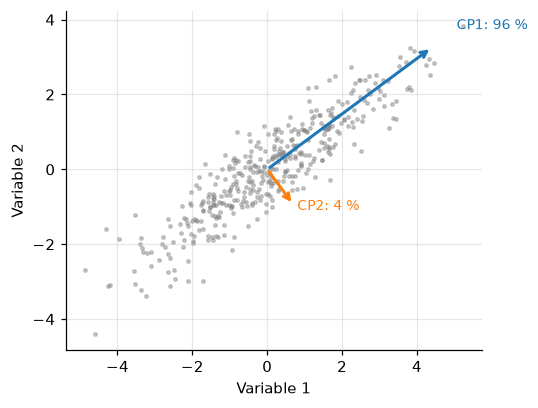

**Figura 4.** PCA en dos dimensiones: la primera componente principal (CP1) sigue la dirección de mayor varianza y recoge la mayor parte de la información; la CP2 es perpendicular.

In [5]:
pca_rng = np.random.default_rng(SEED)
cloud = pca_rng.multivariate_normal([0, 0], [[3.0, 2.2], [2.2, 2.0]], size=400)
centered = cloud - cloud.mean(0)
_, s_vals, Vt = np.linalg.svd(centered, full_matrices=False)
explained = s_vals**2 / np.sum(s_vals**2)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(cloud[:, 0], cloud[:, 1], s=5, alpha=0.4, color="0.5")
for k in range(2):
    d = Vt[k] * 2.5 * s_vals[k] / np.sqrt(len(cloud))
    ax.annotate("", xy=d, xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2, color=f"C{k}"))
    ax.text(*(d * 1.15), f"CP{k + 1}: {100 * explained[k]:.0f} %", color=f"C{k}", fontsize=9)
ax.set(xlabel="Variable 1", ylabel="Variable 2", aspect="equal")
show_figure(fig, 4, "PCA en dos dimensiones: la primera componente principal (CP1) sigue la dirección de mayor varianza y "
                    "recoge la mayor parte de la información; la CP2 es perpendicular.")

<a id="m-wass"></a>
### 4.4 Distancia de Wasserstein entre distribuciones

Qué es la distancia de Wasserstein y por qué se eligió está en la [ficha 3.4](#c-wass). Su definición general (Ec. 9 del artículo) es:

$$W_p(P, Q_k) = \left(\inf_{\pi \in \Gamma(P, Q_k)} \int_{\mathbb{R}^n \times \mathbb{R}^n} \lVert X - Y \rVert^p \, d\pi \right)^{1/p} \tag{11}$$

donde $P$ y $Q_k$ son las distribuciones de la línea base y del caso $k$, $X \sim P$ e $Y \sim Q_k$ son muestras de cada una, $\pi$ es un "plan de transporte" (una distribución conjunta cuyas marginales son $P$ y $Q_k$), $\Gamma(P, Q_k)$ el conjunto de todos esos planes, $\inf$ el mínimo y $p \ge 1$ el orden.

**Cómo se calcula aquí.** El artículo no dice qué $p$ usa ni cómo calcula la distancia en varias dimensiones. Aquí se usa $p = 2$ y se supone que las componentes principales son **normales multivariadas**, porque en ese caso hay fórmula cerrada:

$$W_2^2 = \lVert \boldsymbol{\mu}_P - \boldsymbol{\mu}_Q \rVert^2 + \operatorname{tr}\!\left(\boldsymbol{\Sigma}_P + \boldsymbol{\Sigma}_Q - 2\left(\boldsymbol{\Sigma}_Q^{1/2}\,\boldsymbol{\Sigma}_P\,\boldsymbol{\Sigma}_Q^{1/2}\right)^{1/2}\right) \tag{12}$$

donde $\boldsymbol{\mu}$ y $\boldsymbol{\Sigma}$ son el vector de medias y la matriz de covarianza de cada distribución. El primer término mide cuánto se movió el centro y el segundo cuánto cambió la dispersión.

La Figura 5 compara la distancia de Wasserstein con la divergencia KL entre dos normales de una dimensión, $\mathcal{N}(0, 1)$ y $\mathcal{N}(\delta, 1)$: $W_2 = |\delta|$ crece en línea recta con el desplazamiento $\delta$, mientras que $D_{KL} = \delta^2/2$ crece con el cuadrado.

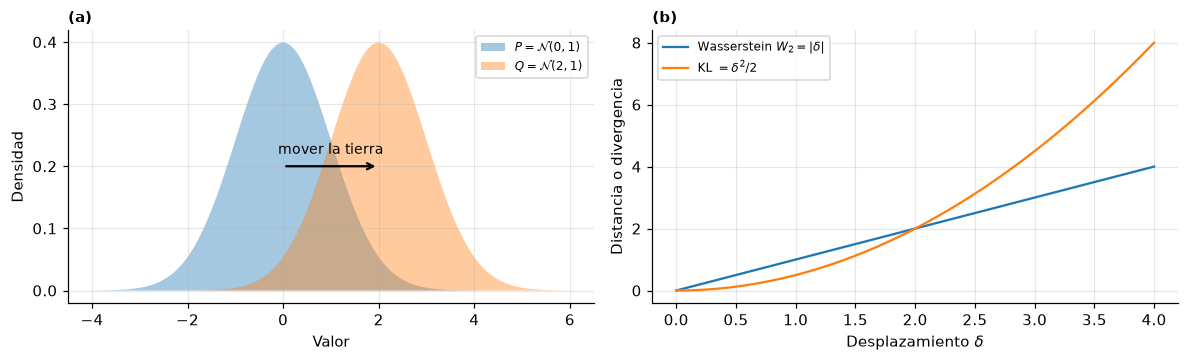

**Figura 5.** (a) La distancia de Wasserstein mide el trabajo de desplazar una distribución hasta la otra. (b) Frente a un desplazamiento $\delta$, Wasserstein crece en forma lineal y KL en forma cuadrática.

In [6]:
def gaussian_w2(T_p, T_q):
    # Eq. (12): 2-Wasserstein distance between normal fits of two sample matrices (rows = vehicles)
    mu_p, mu_q = T_p.mean(0), T_q.mean(0)
    cov_p, cov_q = np.cov(T_p, rowvar=False), np.cov(T_q, rowvar=False)
    root_q = sqrtm(cov_q).real
    cross = sqrtm(root_q @ cov_p @ root_q).real
    return np.sqrt(max(np.sum((mu_p - mu_q)**2) + np.trace(cov_p + cov_q - 2 * cross), 0.0))


delta = np.linspace(0, 4, 100)
x_pdf = np.linspace(-4, 6, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].fill_between(x_pdf, norm.pdf(x_pdf, 0, 1), alpha=0.4, label="$P = \\mathcal{N}(0, 1)$")
axes[0].fill_between(x_pdf, norm.pdf(x_pdf, 2, 1), alpha=0.4, label="$Q = \\mathcal{N}(2, 1)$")
axes[0].annotate("", xy=(2, 0.2), xytext=(0, 0.2), arrowprops=dict(arrowstyle="->", lw=1.5))
axes[0].text(1, 0.22, "mover la tierra", ha="center", fontsize=9)
axes[0].set(xlabel="Valor", ylabel="Densidad")
axes[0].legend(fontsize=8)
axes[1].plot(delta, delta, label="Wasserstein $W_2 = |\\delta|$")
axes[1].plot(delta, delta**2 / 2, label="KL $= \\delta^2/2$")
axes[1].set(xlabel="Desplazamiento $\\delta$", ylabel="Distancia o divergencia")
axes[1].legend(fontsize=8)
for ax, tag in zip(axes, "ab"):
    ax.text(0.0, 1.03, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout()
show_figure(fig, 5, "(a) La distancia de Wasserstein mide el trabajo de desplazar una distribución hasta la otra. "
                    "(b) Frente a un desplazamiento $\\delta$, Wasserstein crece en forma lineal y KL en forma cuadrática.")

<a id="m-di"></a>
### 4.5 Índice de daño

La distancia de Wasserstein por sí sola no dice si un valor es "grande": depende de la cantidad de datos, del ruido y de las unidades. Por eso se normaliza con la distancia entre la línea base y un **conjunto de validación** sano (Ec. 10 del artículo):

$$\text{DI} = \frac{W_p(P,\ Q_{\text{desconocido}})}{W_p(P,\ Q_{\text{validación}})} \tag{13}$$

- $\text{DI} \approx 1$: el caso desconocido se parece a la línea base tanto como otro conjunto de datos sanos → **sin daño**.
- $\text{DI} > 1$: el caso desconocido se aleja más de lo que se alejan dos conjuntos sanos → **anomalía o daño**.

El artículo no fija un umbral de decisión en los estudios numérico y de laboratorio; solo en el caso de campo prueba umbrales de 1.05 y 1.10 (sección 6.4).

<a id="procedimiento"></a>
## 5. Procedimiento

El artículo valida el método en tres niveles: un **modelo numérico** (Sección 3), un **puente de laboratorio** (Sección 4) y **datos reales** del Golden Gate (Sección 5). Este notebook reproduce el modelo numérico con una simulación propia simplificada; del laboratorio y del Golden Gate se describen el montaje y los datos.

<a id="p-puente"></a>
### 5.1 Puente numérico y escenarios de daño

**Artículo:** viga simplemente apoyada de concreto de 25 m, sin amortiguamiento, modelada en Abaqus con 16 elementos: $\rho = 2400$ kg/m³, $E = 27.5$ GPa, $A = 2.0$ m², $I = 0.12$ m⁴. Sus tres primeras frecuencias son 2.08, 8.33 y 18.75 Hz. Para una viga simplemente apoyada de Euler–Bernoulli:

$$f_n = \frac{n^2 \pi}{2L^2}\sqrt{\frac{EI}{\rho A}} \tag{14}$$

donde $L$ es la luz y $n$ el número del modo. El daño se simula reduciendo el módulo de elasticidad de un elemento (1/16 de la luz):

**Tabla 2.** Escenarios de daño del modelo numérico (Sección 3.2 y Tabla 2 del artículo).

| Caso | Ubicación | Cambio |
|---|---|---|
| DC0 | — | Puente sano (línea base) |
| DC1a / DC1b | Centro de luz | Rigidez −15 % / −30 % |
| DC2a / DC2b | 1/4 de la luz | Rigidez −15 % / −30 % |
| DC3 | Apoyos | Articulados → empotrados |

**Aquí:** viga de Euler–Bernoulli con 100 elementos y 4 modos; el daño reduce $EI$ en un tramo de 1/16 de la luz. La Tabla 3 compara las frecuencias.

In [7]:
E_MOD, RHO, AREA, INERTIA, SPAN, GRAVITY = 27.5e9, 2400.0, 2.0, 0.12, 25.0, 9.81
DMG_LEN = 1 / 16   # one Abaqus element out of 16

# name: (list of (center / L, length / L, stiffness loss), support condition)
CASES = {"DC0": ([], "pinned"),
         "DC1a": ([(0.50, DMG_LEN, 0.15)], "pinned"), "DC1b": ([(0.50, DMG_LEN, 0.30)], "pinned"),
         "DC2a": ([(0.25, DMG_LEN, 0.15)], "pinned"), "DC2b": ([(0.25, DMG_LEN, 0.30)], "pinned"),
         "DC3": ([], "fixed")}
PAPER_F1 = {"DC0": 2.08, "DC1a": 2.06, "DC1b": 2.03, "DC2a": 2.04, "DC2b": 1.98, "DC3": 4.72}


def beam_modes(damage=(), supports="pinned", n_el=100, n_modes=4):
    # Euler-Bernoulli beam: natural frequencies (Hz) and mass-normalized mode shapes at the nodes
    le = SPAN / n_el
    n_dof = 2 * (n_el + 1)
    K = np.zeros((n_dof, n_dof))
    M = np.zeros((n_dof, n_dof))
    x_mid = (np.arange(n_el) + 0.5) * le
    k_e = np.array([[12, 6 * le, -12, 6 * le], [6 * le, 4 * le**2, -6 * le, 2 * le**2],
                    [-12, -6 * le, 12, -6 * le], [6 * le, 2 * le**2, -6 * le, 4 * le**2]]) / le**3
    m_e = RHO * AREA * le / 420 * np.array([[156, 22 * le, 54, -13 * le], [22 * le, 4 * le**2, 13 * le, -3 * le**2],
                                           [54, 13 * le, 156, -22 * le], [-13 * le, -3 * le**2, -22 * le, 4 * le**2]])
    for e in range(n_el):
        EI = E_MOD * INERTIA
        for center, length, loss in damage:
            if abs(x_mid[e] - center * SPAN) <= length * SPAN / 2:
                EI *= 1 - loss
        dofs = slice(2 * e, 2 * e + 4)
        K[dofs, dofs] += EI * k_e
        M[dofs, dofs] += m_e
    restrained = [0, n_dof - 2] if supports == "pinned" else [0, 1, n_dof - 2, n_dof - 1]
    free = np.setdiff1d(np.arange(n_dof), restrained)
    w2, V = eigh(K[np.ix_(free, free)], M[np.ix_(free, free)], subset_by_index=[0, n_modes - 1])
    phi = np.zeros((n_dof, n_modes))
    phi[free] = V
    return np.sqrt(w2) / (2 * np.pi), phi[0::2], np.linspace(0, SPAN, n_el + 1)


n = np.arange(1, 4)
analytic = n**2 * np.pi / (2 * SPAN**2) * np.sqrt(E_MOD * INERTIA / (RHO * AREA))   # Eq. (14)
rows = {}
for name, (dmg, supports) in CASES.items():
    f_fe = beam_modes(dmg, supports)[0]
    rows[name] = {"f1 FE (Hz)": f_fe[0], "f1 artículo (Hz)": PAPER_F1[name], "f2 FE (Hz)": f_fe[1], "f3 FE (Hz)": f_fe[2]}
print("Ec. (14), viga sana:", np.round(analytic, 3), "Hz")
show_table(pd.DataFrame(rows).T, 3, "Frecuencias del puente numérico: modelo de elementos finitos de este notebook frente a la "
                                    "frecuencia fundamental reportada en la Tabla 2 del artículo.", precision=3)

Ec. (14), viga sana: [ 2.084  8.336 18.755] Hz


**Tabla 3.** Frecuencias del puente numérico: modelo de elementos finitos de este notebook frente a la frecuencia fundamental reportada en la Tabla 2 del artículo.

,f1 FE (Hz),f1 artículo (Hz),f2 FE (Hz),f3 FE (Hz)
DC0,2.084,2.080,8.336,18.755
DC1a,2.062,2.060,8.335,18.568
DC1b,2.032,2.030,8.333,18.320
DC2a,2.073,2.040,8.250,18.660
DC2b,2.058,1.980,8.135,18.536
DC3,4.724,4.720,13.022,25.528


**Interpretación.**

- El puente sano y los casos DC1 y DC3 coinciden con el artículo; DC3 (empotrado) más que duplica $f_1$ (2.08 → 4.72 Hz), por eso es un "daño" mucho más severo que los demás.
- Los casos a 1/4 de la luz **no coinciden**. En el modelo de este notebook, el daño en el centro baja $f_1$ más que el daño a 1/4 de la luz, que es lo esperable: el modo 1 tiene su curvatura máxima en el centro. El artículo reporta lo contrario (DC2b: 1.98 Hz frente a DC1b: 2.03 Hz) y con eso explica que el daño a 1/4 de la luz sea "más severo". El artículo no aclara esta diferencia.

<a id="p-vehiculos"></a>
### 5.2 Vehículos simulados

**Artículo:** el vehículo es un sistema masa–resorte de un eje (Fig. 5 del artículo). Para representar distintos vehículos se combinan 7 masas, 7 rigideces y 7 velocidades: $7 \times 7 \times 7 = 343$ configuraciones (Tabla 1 del artículo). Cada respuesta se repite 5 veces con 5 % de ruido gaussiano distinto: **1715 señales** por escenario.

**Tabla 4.** Parámetros de los vehículos simulados (Sección 3.1 del artículo).

| Parámetro | Valores |
|---|---|
| Masa $m$ | 960, 1200, 1440, 1680, 1920, 2160, 2400 kg |
| Rigidez $k$ | 200, 250, 300, 350, 400, 450, 500 kN/m |
| Velocidad $v$ | 28.8, 36.0, 43.2, 50.4, 57.6, 64.8, 72.0 km/h |
| Repeticiones con ruido | 5 (ruido gaussiano de 5 %) |

La frecuencia del vehículo es

$$\omega_v = \sqrt{\frac{k}{m}} \ \ (\text{rad/s}), \qquad f_v = \frac{\omega_v}{2\pi} \ \ (\text{Hz}) \tag{15}$$

In [8]:
masses = np.arange(960, 2401, 240.0)              # kg
stiffs = np.arange(200, 501, 50) * 1e3            # N/m
speeds = np.arange(28.8, 72.01, 7.2) / 3.6        # m/s
veh_m, veh_k, veh_v = [a.ravel() for a in np.meshgrid(masses, stiffs, speeds, indexing="ij")]
omega_v = np.sqrt(veh_k / veh_m)                  # Eq. (15)

show_table(pd.DataFrame({"Mínimo": [omega_v.min(), omega_v.min() / (2 * np.pi), 960 / (RHO * AREA * SPAN) * 100],
                         "Máximo": [omega_v.max(), omega_v.max() / (2 * np.pi), 2400 / (RHO * AREA * SPAN) * 100],
                         "Artículo": ["9.13–22.82 'Hz'", "—", "0.8–2 %"]},
                        index=["ω_v (rad/s)", "f_v (Hz)", "Masa vehículo / masa puente (%)"]), 5,
           f"Rango de frecuencias de los {veh_m.size} vehículos con la Ec. (15) y relación de masas, frente a lo reportado.")

**Tabla 5.** Rango de frecuencias de los 343 vehículos con la Ec. (15) y relación de masas, frente a lo reportado.

,Mínimo,Máximo,Artículo
ω_v (rad/s),9.13,22.82,9.13–22.82 'Hz'
f_v (Hz),1.45,3.63,—
Masa vehículo / masa puente (%),0.80,2.00,0.8–2 %


**Interpretación.** El rango que el artículo reporta como "9.13 a 22.82 Hz" coincide exactamente con $\omega_v$ en **rad/s**. En Hz, los vehículos vibran entre 1.45 y 3.63 Hz, es decir, **alrededor de $f_1$ del puente** (2.08 Hz), no muy por encima de él. Lo mismo ocurre en el laboratorio (11.05–28.43 "Hz" son rad/s). La relación de masas sí coincide (0.8–2 %).

<a id="p-vbi"></a>
### 5.3 Interacción vehículo–puente y señales

**Artículo:** análisis dinámico paso a paso en Abaqus, sin rugosidad del pavimento (condiciones ideales) y sin amortiguamiento. Las señales se registran a 100 Hz y luego se **submuestrean a 40 Hz**, el doble de $f_3$ (2 × 18.75 Hz): la frecuencia de Nyquist. Esa señal de 40 Hz es la "original" (CL = 0 %).

**Aquí:** superposición modal con 4 modos acoplada con el vehículo e integrada con Runge–Kutta de orden 4. Con $y$ el desplazamiento del vehículo, $q_n$ la coordenada del modo $n$ del puente, $\phi_n(x)$ su forma modal (normalizada a masa unitaria) y $x = vt$ la posición del vehículo:

$$m\,\ddot{y} = F_s, \qquad F_s = k\left(\textstyle\sum_n \phi_n(x)\,q_n - y\right), \qquad \ddot{q}_n + \omega_n^2\, q_n = -\phi_n(x)\,(m g + F_s) \tag{16}$$

donde $F_s$ es la fuerza del resorte, $\omega_n$ la frecuencia angular del modo $n$ y $g$ la gravedad. La aceleración que registra el teléfono es $\ddot{y}$.

In [9]:
def simulate_crossings(damage, supports, fs=100.0, substeps=10):
    # Vehicle accelerations (100 Hz) for the 343 vehicle configurations, Eq. (16), no damping, no roughness
    freqs, phi, x_nodes = beam_modes(damage, supports)
    w = 2 * np.pi * freqs
    p, n_modes = veh_m.size, w.size
    dt = 1 / fs / substeps
    t_cross = SPAN / veh_v
    n_steps = int(np.ceil(t_cross.max() / dt)) + 1

    def rhs(t, y, yd, q, qd):
        x = veh_v * t
        on = x <= SPAN
        Phi = np.stack([np.interp(x, x_nodes, phi[:, n]) for n in range(n_modes)], axis=1) * on[:, None]
        Fs = veh_k * ((Phi * q).sum(1) - y)
        return yd, Fs / veh_m, qd, -w**2 * q - Phi * ((veh_m * GRAVITY + Fs) * on)[:, None]

    state = [np.zeros(p), np.zeros(p), np.zeros((p, n_modes)), np.zeros((p, n_modes))]
    acc = []
    for step in range(n_steps):
        t = step * dt
        k1 = rhs(t, *state)
        k2 = rhs(t + dt / 2, *[s + dt / 2 * d for s, d in zip(state, k1)])
        k3 = rhs(t + dt / 2, *[s + dt / 2 * d for s, d in zip(state, k2)])
        k4 = rhs(t + dt, *[s + dt * d for s, d in zip(state, k3)])
        if step % substeps == 0:
            acc.append(k1[1])
        state = [s + dt / 6 * (a + 2 * b + 2 * c + d) for s, a, b, c, d in zip(state, k1, k2, k3, k4)]
    acc = np.array(acc).T
    return [acc[i, :int(t_cross[i] * fs)] for i in range(p)]


N_REPEAT, NOISE = 5, 0.05
sim_rng = np.random.default_rng(SEED)
start = time.time()
signals_40hz = {}   # case -> list of 1715 noisy signals at 40 Hz
for name, (dmg, supports) in CASES.items():
    clean = [resample_poly(a, 2, 5) for a in simulate_crossings(dmg, supports)]   # 100 Hz -> 40 Hz
    signals_40hz[name] = [a + NOISE * a.std() * sim_rng.standard_normal(a.size) for _ in range(N_REPEAT) for a in clean]
print(f"{len(CASES)} casos x {len(signals_40hz['DC0'])} señales simulados en {time.time() - start:.0f} s")

6 casos x 1715 señales simulados en 4 s


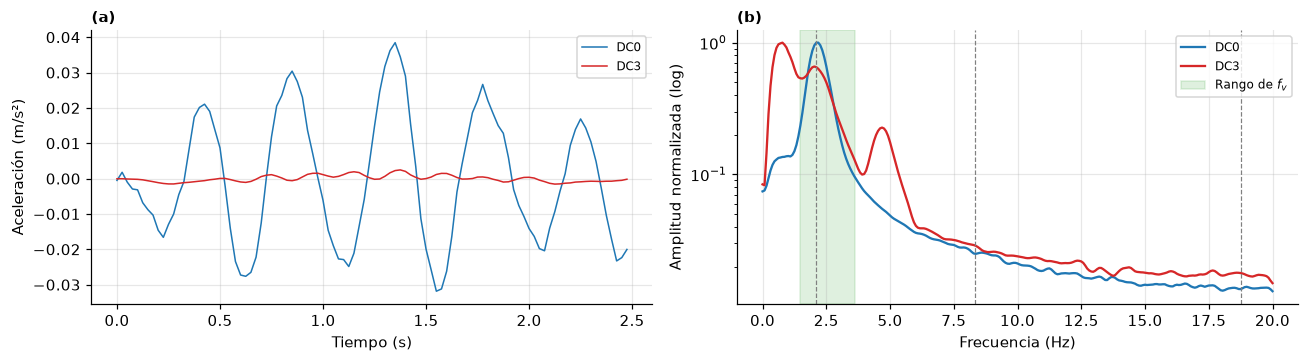

**Figura 6.** Señales simuladas a 40 Hz. (a) Aceleración del vehículo de ejemplo del artículo (1200 kg, 500 kN/m, 36 km/h) en el puente sano y con apoyos empotrados. (b) Espectro promedio de los 343 vehículos; líneas grises: frecuencias del puente sano.

In [10]:
# Example vehicle of the paper (Fig. 7): m = 1200 kg, k = 500 kN/m, v = 36 km/h
EXAMPLE = int(np.flatnonzero((veh_m == 1200) & (veh_k == 500e3) & np.isclose(veh_v, 10.0))[0])
f_fft = np.fft.rfftfreq(512, 1 / FS)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for name, color in [("DC0", "C0"), ("DC3", "C3")]:
    a = signals_40hz[name][EXAMPLE]
    axes[0].plot(np.arange(a.size) / FS, a, color=color, lw=1, label=name)
    mean_spec = np.mean([np.interp(f_fft, np.fft.rfftfreq(512, 1 / FS), np.abs(np.fft.rfft(s, 512)))
                         for s in signals_40hz[name][:343]], axis=0)
    axes[1].semilogy(f_fft, mean_spec / mean_spec.max(), color=color, label=name)
for fn in beam_modes()[0][:3]:
    axes[1].axvline(fn, color="0.5", ls="--", lw=0.8)
axes[1].axvspan(omega_v.min() / (2 * np.pi), omega_v.max() / (2 * np.pi), color="C2", alpha=0.15, label="Rango de $f_v$")
axes[0].set(xlabel="Tiempo (s)", ylabel="Aceleración (m/s²)")
axes[1].set(xlabel="Frecuencia (Hz)", ylabel="Amplitud normalizada (log)")
for ax, tag in zip(axes, "ab"):
    ax.legend(fontsize=8)
    ax.text(0.0, 1.03, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout()
show_figure(fig, 6, "Señales simuladas a 40 Hz. (a) Aceleración del vehículo de ejemplo del artículo (1200 kg, 500 kN/m, 36 km/h) "
                    "en el puente sano y con apoyos empotrados. (b) Espectro promedio de los 343 vehículos; líneas grises: "
                    "frecuencias del puente sano.")

**Interpretación.** La respuesta del vehículo está dominada por las frecuencias bajas: la del propio vehículo (1.45–3.63 Hz) y $f_1$ del puente. Con apoyos empotrados (DC3) el puente es mucho más rígido y la respuesta cambia de forma visible. Una señal dominada por pocas frecuencias es **dispersa**, condición necesaria para el compressed sensing.

<a id="p-cs"></a>
### 5.4 Compresión de las señales

**Artículo** (Sección 3.3): se consideran tres niveles de compresión, CL = 20, 50 y 80 %. Por ejemplo, CL = 80 % significa que de la señal de 40 Hz se conserva al azar solo el 20 % de las muestras. En la práctica el teléfono guardaría directamente esas muestras; en el estudio se simula submuestreando al azar la señal de 40 Hz. Todas las señales (línea base, validación y casos dañados) se comprimen y se reconstruyen con la Ec. (4).

**Aquí** se hace lo mismo con las 1715 señales de cada caso. La celda tarda alrededor de medio minuto.

In [11]:
CLS = [0.0, 0.2, 0.5, 0.8]
cs_rng = np.random.default_rng(SEED)
start = time.time()
features = {}   # (cl, case) -> MFCC matrix U (1715 x 20)
for cl in CLS:
    for name in CASES:
        sigs = signals_40hz[name] if cl == 0 else [cs_reconstruct(a, cl, cs_rng)[0] for a in signals_40hz[name]]
        features[cl, name] = np.array([mfcc(a) for a in sigs])
print(f"Reconstrucción y MFCC de {len(CLS)} niveles x {len(CASES)} casos en {time.time() - start:.0f} s")

Reconstrucción y MFCC de 4 niveles x 6 casos en 33 s


<a id="p-runs"></a>
### 5.5 Características, PCA y repeticiones

**Artículo** (Algoritmo 2): para cada nivel de compresión se repite 30 veces:

1. Se elige al azar el 50 % de las señales sanas como **línea base** y el otro 50 % como **validación**; del caso desconocido se toma al azar el 50 %. Así se imita que los vehículos que cruzan en distintos momentos no son exactamente los mismos.
2. MFCC → PCA → distribuciones → distancia de Wasserstein entre la línea base y la validación, y entre la línea base y el caso desconocido.

Al final, el DI del caso es el promedio de las distancias del caso desconocido dividido por el promedio de las de validación, Ec. (13). Para ver la dispersión, cada ensayo también se divide por ese promedio de validación (Figs. 8–10 del artículo).

**Aquí:** PCA ajustada con la línea base y $q = 10$ componentes (el artículo no reporta $q$). La Figura 7 muestra cuánta varianza recoge cada componente.

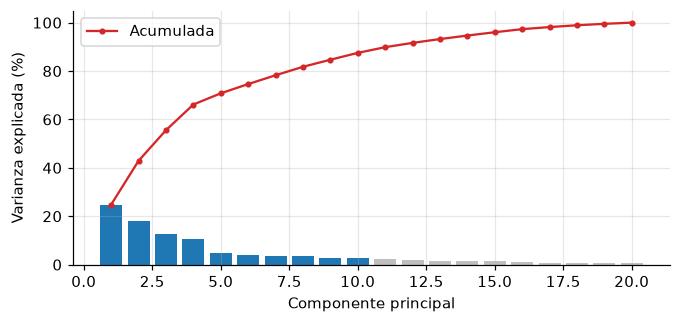

**Figura 7.** Varianza explicada por cada componente principal de los MFCC del puente sano (CL = 0 %). En azul, las 10 componentes que se conservan (88 % de la varianza).

In [12]:
N_PC, N_RUNS = 10, 30


def fit_pca(U):
    # Standardize with the baseline and keep the first N_PC principal directions, Eq. (10)
    mu, sd = U.mean(0), U.std(0)
    _, s_vals, Vt = np.linalg.svd((U - mu) / sd, full_matrices=False)
    return (lambda F: ((F - mu) / sd) @ Vt[:N_PC].T), s_vals**2 / np.sum(s_vals**2)


_, explained = fit_pca(features[0.0, "DC0"])
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(np.arange(1, N_MFCC + 1), 100 * explained, color=["C0"] * N_PC + ["0.75"] * (N_MFCC - N_PC))
ax.plot(np.arange(1, N_MFCC + 1), 100 * np.cumsum(explained), "o-", ms=3, color="C3", label="Acumulada")
ax.set(xlabel="Componente principal", ylabel="Varianza explicada (%)")
ax.legend()
show_figure(fig, 7, f"Varianza explicada por cada componente principal de los MFCC del puente sano (CL = 0 %). "
                    f"En azul, las {N_PC} componentes que se conservan ({100 * explained[:N_PC].sum():.0f} % de la varianza).")

run_rng = np.random.default_rng(SEED)
n_sig = features[0.0, "DC0"].shape[0]
w_val = {cl: [] for cl in CLS}
w_unk = {(cl, name): [] for cl in CLS for name in CASES if name != "DC0"}
for cl in CLS:
    U0 = features[cl, "DC0"]
    for run in range(N_RUNS):
        perm = run_rng.permutation(n_sig)
        base, val = perm[:n_sig // 2], perm[n_sig // 2:]
        project, _ = fit_pca(U0[base])
        T_base = project(U0[base])
        w_val[cl].append(gaussian_w2(T_base, project(U0[val])))
        for name in CASES:
            if name != "DC0":
                pick = run_rng.choice(n_sig, n_sig // 2, replace=False)
                w_unk[cl, name].append(gaussian_w2(T_base, project(features[cl, name][pick])))

# Damage index, Eq. (13): each run divided by the mean validation distance
di_runs = {(cl, "DC0"): np.array(w_val[cl]) / np.mean(w_val[cl]) for cl in CLS}
di_runs.update({key: np.array(v) / np.mean(w_val[key[0]]) for key, v in w_unk.items()})

<a id="p-lab"></a>
### 5.6 Experimento de laboratorio

No se puede reproducir aquí; se resume el montaje (Sección 4.1 del artículo).

**Tabla 6.** Montaje del experimento de laboratorio.

| Elemento | Detalle |
|---|---|
| Puente | Placa de acero simplemente apoyada: luz 2 m, ancho 330 mm, espesor 6.35 mm, $E$ = 200 GPa |
| Frecuencias (prueba de impacto) | 3.71, 14.9 y 33.4 Hz |
| Vehículo | Robot de dos placas de aluminio con suspensión; velocidad controlada con Arduino |
| Sensores | 2 acelerómetros inalámbricos G-Link-200 (128 Hz, se promedian) y un teléfono Galaxy S5 (100 Hz) |
| Variantes del vehículo | 5 resortes (155–726 N/m) × 5 masas (0.898–1.270 kg) × 3 velocidades (0.25–0.40 m/s) |
| Ensayos | 75 configuraciones × 3 repeticiones = 225 por estado del puente |
| Submuestreo | A 70 Hz (≈ 2 × 33.4 Hz) antes de comprimir |
| MFCC | 30 por señal |

**Tabla 7.** Escenarios de daño del laboratorio (Tabla 3 del artículo). El daño se hace con cortes en la placa; se pegan barras de acero sueltas para compensar la masa retirada.

| Caso | Ubicación | Reducción de rigidez | Corte (por lado) | $f_1$ (Hz) |
|---|---|---|---|---|
| DC0 | — | — | — | 3.71 |
| DC1a | Centro de luz | 15 % | 24.8 × 250 mm | 3.62 |
| DC1b | Centro de luz | 30 % | 49.5 × 250 mm | 3.52 |
| DC2a | 1/4 de la luz | 15 % | 24.8 × 250 mm | 3.66 |
| DC2b | 1/4 de la luz | 30 % | 49.5 × 250 mm | 3.61 |
| DC3 | Apoyos | Articulado → empotrado (vigas I con 4 pernos) | — | 8.40 |

Igual que en el modelo numérico: 50 % de los ensayos sanos como línea base y 50 % como validación, 50 % de cada caso dañado, y 30 repeticiones.

<a id="p-gg"></a>
### 5.7 Caso de campo: puente Golden Gate

**Datos** (Sección 5.1 del artículo): 102 cruces del puente Golden Gate (California; puente colgante con luz principal de 1280 m y primeras frecuencias de 0.106, 0.132, 0.170 y 0.216 Hz) registrados por Matarazzo et al. (2018) con teléfonos iPhone 5 en dos sedanes (Nissan Sentra y Ford Focus), a 32–64 km/h, en horas pico durante cinco días de junio de 2017. Las señales están remuestreadas a 100 Hz.

**Uso** (Sección 5.2): el puente está **sano** en todos los cruces, así que solo se puede comprobar que el método **no** da falsas alarmas. El 50 % de los cruces se usa como línea base y el otro 50 % como caso "desconocido" (validación); se repite 30 veces. Se espera DI ≈ 1.

<a id="resultados"></a>
## 6. Resultados

Para el modelo numérico se muestra primero la simulación de este notebook y después lo que **reporta el artículo**. Para el laboratorio y el Golden Gate solo hay valores reportados (leídos de las figuras del artículo, aproximados).

<a id="r-recon"></a>
### 6.1 Reconstrucción de señales

Se reconstruye la señal del vehículo de ejemplo (1200 kg, 500 kN/m, 36 km/h) sobre el puente sano con los tres niveles de compresión (Fig. 7 del artículo). La calidad se mide con

$$R^2 = 1 - \frac{\sum_t (x_t - \hat{x}_t)^2}{\sum_t (x_t - \bar{x})^2} \tag{17}$$

donde $x_t$ es la señal original, $\hat{x}_t$ la reconstruida y $\bar{x}$ la media de la original.

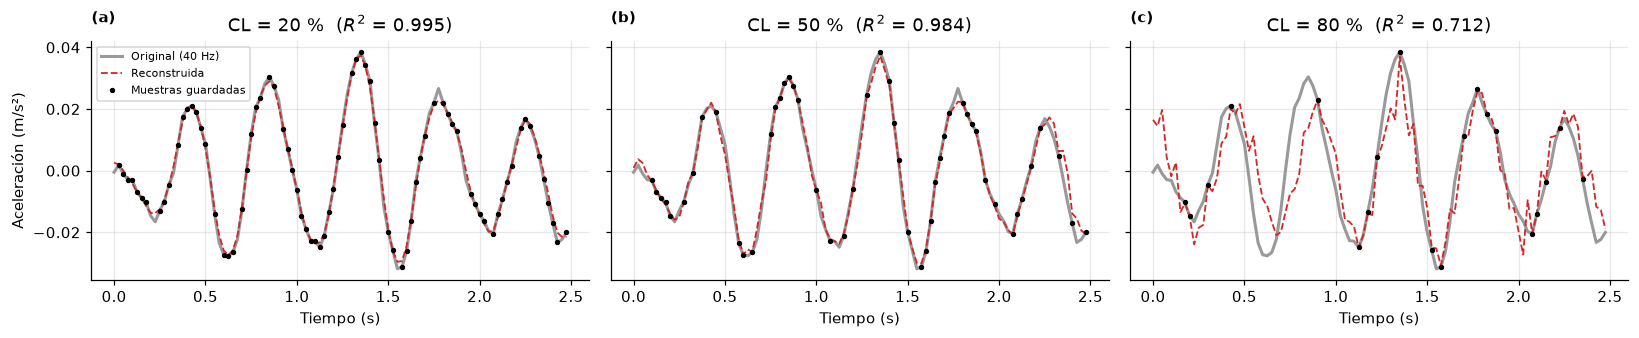

**Figura 8.** Reconstrucción de la señal del vehículo de ejemplo con 20, 50 y 80 % de compresión (equivalente a la Fig. 7 del artículo).

**Tabla 8.** Calidad de la reconstrucción, Ec. (17): simulación de este notebook frente a lo reportado en la Sección 3.4.1 del artículo.

,R² vehículo de ejemplo (simulación),R² mediana de 200 señales (simulación),R² artículo (vehículo de ejemplo)
CL = 20 %,0.995,0.996,0.996
CL = 50 %,0.984,0.981,0.989
CL = 80 %,0.712,0.716,0.957


In [13]:
x_ex = signals_40hz["DC0"][EXAMPLE]
t_ex = np.arange(x_ex.size) / FS
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
r2_ex = {}
for ax, cl, tag in zip(axes, [0.2, 0.5, 0.8], "abc"):
    x_hat, kept = cs_reconstruct(x_ex, cl, np.random.default_rng(SEED))
    r2_ex[cl] = r_squared(x_ex, x_hat)                                       # Eq. (17)
    ax.plot(t_ex, x_ex, color="0.6", lw=2, label="Original (40 Hz)")
    ax.plot(t_ex, x_hat, "--", color="C3", lw=1.2, label="Reconstruida")
    ax.plot(t_ex[kept], x_ex[kept], "o", ms=2.5, color="k", label="Muestras guardadas")
    ax.set(xlabel="Tiempo (s)", title=f"CL = {int(cl * 100)} %  ($R^2$ = {r2_ex[cl]:.3f})")
    ax.text(0.0, 1.08, f"({tag})", transform=ax.transAxes, fontweight="bold")
axes[0].set_ylabel("Aceleración (m/s²)")
axes[0].legend(fontsize=7)
fig.tight_layout()
show_figure(fig, 8, "Reconstrucción de la señal del vehículo de ejemplo con 20, 50 y 80 % de compresión "
                    "(equivalente a la Fig. 7 del artículo).")

recon_rng = np.random.default_rng(SEED)
sample_idx = recon_rng.choice(n_sig, 200, replace=False)
r2_median = {cl: np.median([r_squared(signals_40hz["DC0"][i], cs_reconstruct(signals_40hz["DC0"][i], cl, recon_rng)[0])
                            for i in sample_idx]) for cl in [0.2, 0.5, 0.8]}
show_table(pd.DataFrame({"R² vehículo de ejemplo (simulación)": r2_ex,
                         "R² mediana de 200 señales (simulación)": r2_median,
                         "R² artículo (vehículo de ejemplo)": {0.2: 0.996, 0.5: 0.989, 0.8: 0.957}}
                        ).rename(index=lambda c: f"CL = {int(c * 100)} %"), 8,
           "Calidad de la reconstrucción, Ec. (17): simulación de este notebook frente a lo reportado en la Sección 3.4.1 del artículo.",
           precision=3)

**Interpretación.** Con 20 y 50 % de compresión la señal se recupera casi exactamente. Con 80 % (solo una de cada cinco muestras, en promedio a 8 Hz, por debajo del doble de $f_3$) la reconstrucción conserva la forma general pero pierde detalle; en la simulación pierde más que en el ejemplo del artículo ($R^2$ = 0.957), en parte porque aquí el 5 % de ruido, que no es disperso, se incluye en la señal a reconstruir.

<a id="r-num"></a>
### 6.2 Índice de daño en el modelo numérico

Cada punto es un ensayo (30 por caso y nivel de compresión); el DI de DC0 (validación) queda alrededor de 1 por construcción (Figs. 8–10 del artículo).

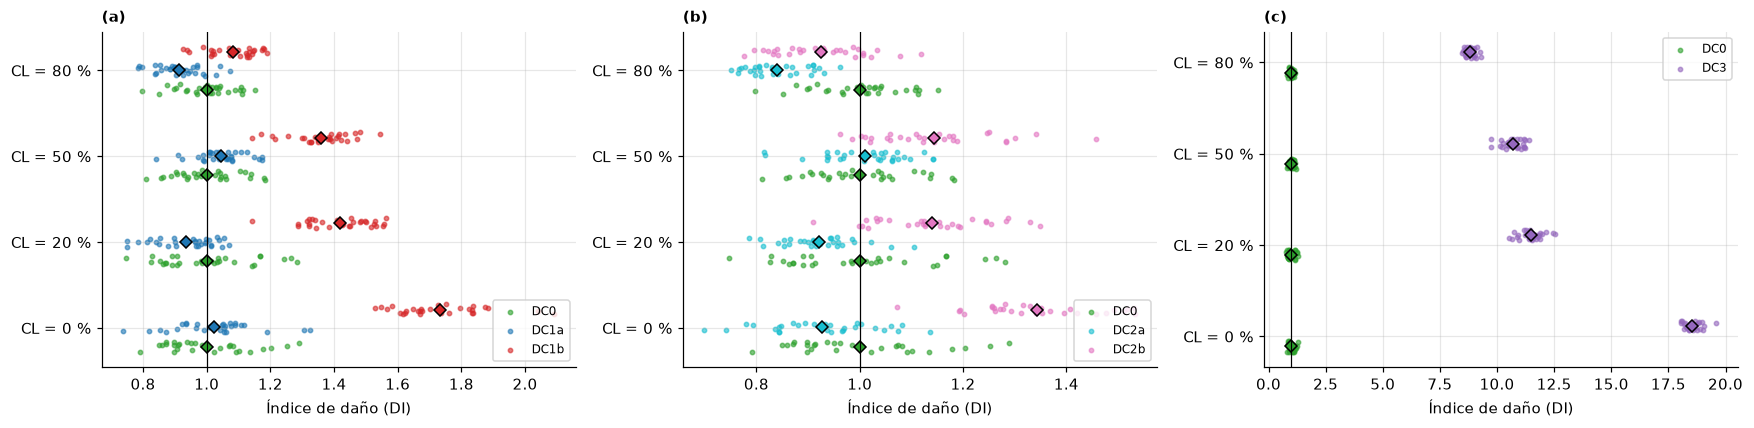

**Figura 9.** DI simulado en los 30 ensayos (puntos) y su promedio (rombos). (a) Daño en el centro de luz. (b) Daño a 1/4 de la luz. (c) Cambio de apoyos (equivalente a las Figs. 8–10 del artículo).

In [14]:
def strip_plot(ax, names, colors, legend_loc="lower right"):
    for k, (name, color) in enumerate(zip(names, colors)):
        for j, cl in enumerate(CLS):
            d = di_runs[cl, name]
            yy = j + (k - (len(names) - 1) / 2) * 0.22 + np.random.default_rng(k * 10 + j).uniform(-0.06, 0.06, d.size)
            ax.scatter(d, yy, s=8, alpha=0.6, color=color, label=name if j == 0 else None)
            ax.plot(d.mean(), yy.mean(), "D", ms=6, color=color, mec="k")
    ax.axvline(1.0, color="k", lw=0.8)
    ax.set_yticks(range(len(CLS)), [f"CL = {int(c * 100)} %" for c in CLS])
    ax.set_xlabel("Índice de daño (DI)")
    ax.legend(fontsize=8, loc=legend_loc)


fig, axes = plt.subplots(1, 3, figsize=(16, 4))
strip_plot(axes[0], ["DC0", "DC1a", "DC1b"], ["C2", "C0", "C3"])
strip_plot(axes[1], ["DC0", "DC2a", "DC2b"], ["C2", "C9", "C6"])
strip_plot(axes[2], ["DC0", "DC3"], ["C2", "C4"], legend_loc="upper right")
for ax, tag in zip(axes, "abc"):
    ax.text(0.0, 1.03, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout()
show_figure(fig, 9, "DI simulado en los 30 ensayos (puntos) y su promedio (rombos). (a) Daño en el centro de luz. "
                    "(b) Daño a 1/4 de la luz. (c) Cambio de apoyos (equivalente a las Figs. 8–10 del artículo).")

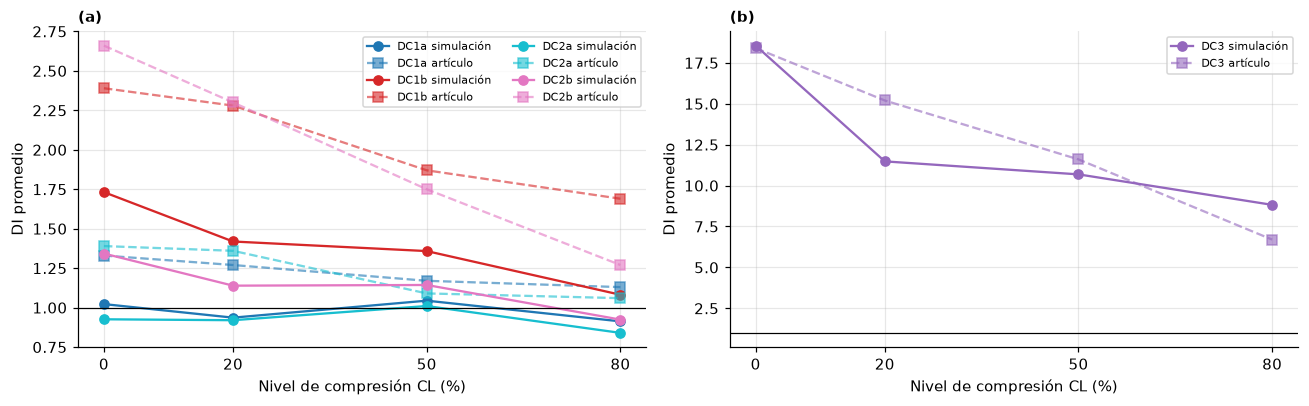

**Figura 10.** DI promedio según el nivel de compresión: simulación de este notebook (líneas continuas) y valores leídos de la Fig. 11 del artículo (líneas discontinuas). (a) Daños en el vano. (b) Cambio de apoyos.

**Tabla 9.** DI promedio del modelo numérico: simulación de este notebook frente a los valores aproximados de la Fig. 11 del artículo.

,Sim. CL=0 %,Sim. CL=20 %,Sim. CL=50 %,Sim. CL=80 %,Art. CL=0 %,Art. CL=20 %,Art. CL=50 %,Art. CL=80 %
DC1a,1.02,0.94,1.04,0.91,1.33,1.27,1.17,1.13
DC1b,1.73,1.42,1.36,1.08,2.39,2.28,1.87,1.69
DC2a,0.93,0.92,1.01,0.84,1.39,1.36,1.09,1.06
DC2b,1.34,1.14,1.14,0.92,2.66,2.30,1.75,1.27
DC3,18.55,11.48,10.69,8.82,18.40,15.20,11.60,6.70


In [15]:
PAPER_DI = {  # numerical model, read from Fig. 11 of the paper (approximate), CL = 0, 20, 50, 80 %
    "DC1a": [1.33, 1.27, 1.17, 1.13], "DC1b": [2.39, 2.28, 1.87, 1.69],
    "DC2a": [1.39, 1.36, 1.09, 1.06], "DC2b": [2.66, 2.30, 1.75, 1.27], "DC3": [18.4, 15.2, 11.6, 6.7]}
sim_di = {name: [np.mean(w_unk[cl, name]) / np.mean(w_val[cl]) for cl in CLS] for name in PAPER_DI}   # Eq. (13)

cl_pct = [int(c * 100) for c in CLS]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, color in zip(["DC1a", "DC1b", "DC2a", "DC2b"], ["C0", "C3", "C9", "C6"]):
    axes[0].plot(cl_pct, sim_di[name], "o-", color=color, label=f"{name} simulación")
    axes[0].plot(cl_pct, PAPER_DI[name], "s--", color=color, alpha=0.6, label=f"{name} artículo")
axes[1].plot(cl_pct, sim_di["DC3"], "o-", color="C4", label="DC3 simulación")
axes[1].plot(cl_pct, PAPER_DI["DC3"], "s--", color="C4", alpha=0.6, label="DC3 artículo")
for ax, tag in zip(axes, "ab"):
    ax.axhline(1.0, color="k", lw=0.8)
    ax.set(xlabel="Nivel de compresión CL (%)", ylabel="DI promedio", xticks=cl_pct)
    ax.legend(fontsize=7, ncol=2 if tag == "a" else 1)
    ax.text(0.0, 1.03, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout()
show_figure(fig, 10, "DI promedio según el nivel de compresión: simulación de este notebook (líneas continuas) y valores "
                     "leídos de la Fig. 11 del artículo (líneas discontinuas). (a) Daños en el vano. (b) Cambio de apoyos.")

table = pd.DataFrame({f"Sim. CL={p} %": [sim_di[n_][k] for n_ in PAPER_DI] for k, p in enumerate(cl_pct)}, index=list(PAPER_DI))
for k, p in enumerate(cl_pct):
    table[f"Art. CL={p} %"] = [PAPER_DI[n_][k] for n_ in PAPER_DI]
show_table(table, 9, "DI promedio del modelo numérico: simulación de este notebook frente a los valores aproximados de la "
                     "Fig. 11 del artículo.")

**Reportado por el artículo (Figs. 8–11):**

- Los daños de **30 %** (DC1b, DC2b) se detectan con claridad en todos los niveles de compresión, y su DI es mayor que el de los daños de 15 %: el índice refleja la **severidad**.
- Los daños de **15 %** (DC1a, DC2a) tienen DI promedio de 1.3–1.4 sin compresión, pero con CL = 50–80 % sus ensayos se mezclan con los de validación; solo el promedio de los 30 ensayos sigue por encima de 1.
- El cambio de apoyos (DC3) da un DI unas 5 veces mayor que los demás casos (≈ 18 sin compresión).
- **Al aumentar la compresión, el DI baja** en todos los casos: se pierde información de daño. Con CL ≤ 20 % la severidad se distingue igual que con la señal original.

**Interpretación (simulación).**

- **Coincide con el artículo:** DC3 da un DI casi igual al reportado sin compresión (≈ 18.5 frente a ≈ 18.4), y el DI baja al aumentar la compresión.
- **Daños de 30 %:** se detectan con CL ≤ 50 % (DI ≈ 1.1–1.7), pero con CL = 80 % su DI cae a ≈ 0.9–1.1 y se pierden.
- **Daños de 15 %:** su DI queda alrededor de 1 en todos los niveles, es decir, **no se detectan**.
- **Ubicación:** el daño a 1/4 de la luz resulta menos visible que en el centro, al revés que en el artículo pero de acuerdo con las frecuencias de la Tabla 3.

El margen de detección depende de detalles que el artículo no reporta: número de componentes PCA, cálculo de Wasserstein y regularización de la reconstrucción.

<a id="r-lab"></a>
### 6.3 Índice de daño en el laboratorio

Valores reportados por el artículo (Figs. 14–17), leídos de las gráficas, para los acelerómetros inalámbricos y el teléfono.

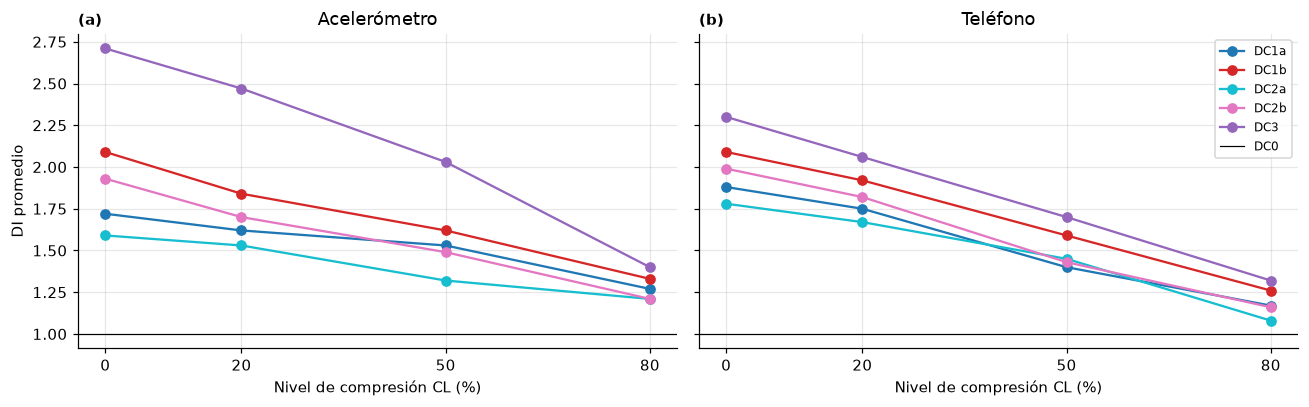

**Figura 11.** DI promedio del experimento de laboratorio según el nivel de compresión: (a) acelerómetros inalámbricos y (b) teléfono. Valores leídos de la Fig. 17 del artículo (aproximados).

In [16]:
LAB_DI = {  # mean DI read from Fig. 17 of the paper (approximate), CL = 0, 20, 50, 80 %
    "Acelerómetro": {"DC1a": [1.72, 1.62, 1.53, 1.27], "DC1b": [2.09, 1.84, 1.62, 1.33], "DC2a": [1.59, 1.53, 1.32, 1.21],
                     "DC2b": [1.93, 1.70, 1.49, 1.21], "DC3": [2.71, 2.47, 2.03, 1.40]},
    "Teléfono": {"DC1a": [1.88, 1.75, 1.40, 1.17], "DC1b": [2.09, 1.92, 1.59, 1.26], "DC2a": [1.78, 1.67, 1.45, 1.08],
                 "DC2b": [1.99, 1.82, 1.43, 1.16], "DC3": [2.30, 2.06, 1.70, 1.32]},
}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (sensor, values), tag in zip(axes, LAB_DI.items(), "ab"):
    for name, color in zip(values, ["C0", "C3", "C9", "C6", "C4"]):
        ax.plot(cl_pct, values[name], "o-", color=color, label=name)
    ax.axhline(1.0, color="k", lw=0.8, label="DC0")
    ax.set(xlabel="Nivel de compresión CL (%)", xticks=cl_pct, title=sensor)
    ax.text(0.0, 1.03, f"({tag})", transform=ax.transAxes, fontweight="bold")
axes[0].set_ylabel("DI promedio")
axes[1].legend(fontsize=8)
fig.tight_layout()
show_figure(fig, 11, "DI promedio del experimento de laboratorio según el nivel de compresión: (a) acelerómetros inalámbricos y "
                     "(b) teléfono. Valores leídos de la Fig. 17 del artículo (aproximados).")

**Reportado por el artículo (Secciones 4.2.1 y 4.2.2):**

- Todos los daños se detectan, incluso con 80 % de compresión (DI > 1).
- El daño en el **centro** resulta más severo que a 1/4 de la luz, coherente con las frecuencias de la Tabla 7 (en el laboratorio el corte a 1/4 quedó algo más cerca del centro).
- El DI baja al aumentar la compresión; para conservar la **severidad** (que 30 % dé más que 15 %) los autores recomiendan **CL ≤ 20 %**.
- El **teléfono** da DI algo menores y más variables que los acelerómetros, pero sigue detectando el daño.
- DC3 da un DI mucho menor que en el modelo numérico (≈ 2.7 frente a ≈ 18): los apoyos reales no son articulaciones ni empotramientos perfectos.

<a id="r-gg"></a>
### 6.4 Falsas alarmas en el Golden Gate

Como el puente está sano, cualquier DI por encima del umbral es una **falsa alarma**. El artículo prueba dos umbrales (Fig. 20 del artículo).

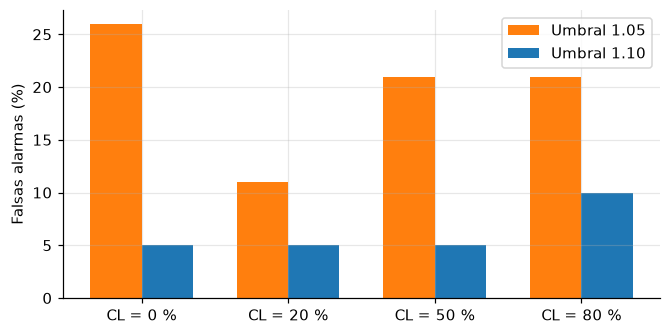

**Figura 12.** Porcentaje de falsas alarmas en los 30 ensayos con datos del Golden Gate (puente sano) para dos umbrales del DI. Valores leídos de la Fig. 20 del artículo (aproximados).

In [17]:
GG_FP = {"Umbral 1.05": [26, 11, 21, 21], "Umbral 1.10": [5, 5, 5, 10]}   # false positives (%) read from Fig. 20
fig, ax = plt.subplots(figsize=(7, 3.4))
width = 0.35
for k, (label, values) in enumerate(GG_FP.items()):
    ax.bar(np.arange(4) + (k - 0.5) * width, values, width, label=label, color=["C1", "C0"][k])
ax.set_xticks(range(4), [f"CL = {p} %" for p in cl_pct])
ax.set_ylabel("Falsas alarmas (%)")
ax.legend()
show_figure(fig, 12, "Porcentaje de falsas alarmas en los 30 ensayos con datos del Golden Gate (puente sano) para dos umbrales "
                     "del DI. Valores leídos de la Fig. 20 del artículo (aproximados).")

**Reportado por el artículo (Figs. 19–21):**

- La distribución de las primeras tres características cambia al comprimir, pero la línea base y la validación siguen pareciéndose: DI ≈ 1 en todos los niveles de compresión.
- Con umbral 1.05 hay **≈ 20 % de falsas alarmas**; con 1.10 bajan a **≈ 5 %** (≈ 10 % con CL = 80 %).
- La dispersión del DI del puente sano en campo (≈ 0.8–1.25) es muy parecida a la del laboratorio con el teléfono (Fig. 21).

**Interpretación.** El caso de campo muestra que el método es **aplicable** con datos reales de teléfonos y que la compresión no genera por sí sola falsas alarmas. Pero no prueba que detecte daño en un puente real: no hay datos del puente dañado. Además, con un umbral de 1.10, los daños de 15 % del laboratorio comprimidos al 80 % (DI ≈ 1.1–1.3) quedarían cerca del límite.

<a id="conclusiones"></a>
## 7. Conclusiones y limitaciones

### Conclusiones del artículo

1. Integrar compressed sensing al monitoreo por crowdsensing **reduce los datos** que cada teléfono guarda y envía sin perder la capacidad de detectar daño.
2. En el modelo numérico y en el laboratorio, el daño se detecta incluso con **80 % de compresión**; para conservar la información de **severidad**, la compresión debe limitarse a **≈ 20 %**.
3. El DI (Wasserstein normalizado) refleja la presencia y la severidad del daño y es reproducible entre ensayos.
4. El marco es poco sensible a la velocidad y a las propiedades de los vehículos; los autores lo atribuyen a la PCA.
5. Con datos reales del Golden Gate, el DI del puente sano queda cerca de 1 y su variación es similar a la del laboratorio: el marco es aplicable en la práctica.

### Limitaciones declaradas por los autores

- Rugosidad del pavimento, tiempo corto de interacción vehículo–puente y efectos ambientales pueden afectar el desempeño.
- Distinguir la severidad del daño es difícil en algunos casos por el ruido ambiental y las limitaciones de los sensores de los teléfonos.
- Trabajo futuro: estudiar la rugosidad de forma sistemática, sumar datos de clima y temperatura, y probar en puentes reales dañados de forma controlada (p. ej. antes de su demolición).

### Limitaciones identificadas en este análisis

- **Frecuencias de los vehículos en unidades equivocadas.** Los rangos "9.13–22.82 Hz" (numérico) y "11.05–28.43 Hz" (laboratorio) son $\omega_v$ en rad/s. En Hz, los vehículos numéricos vibran a 1.45–3.63 Hz, alrededor de $f_1$ del puente, no muy por encima.
- **Frecuencias de daño a 1/4 de la luz poco coherentes.** La Tabla 2 del artículo dice que el daño a 1/4 de la luz baja $f_1$ más que el del centro; para el modo 1 de una viga simplemente apoyada debería ser al revés (Tabla 3 de este notebook). Sobre esa base, el artículo afirma que el daño a 1/4 es "más severo".
- **La compresión se aplica después de medir.** Se submuestrea una señal ya registrada a 40 Hz; un teléfono real sigue muestreando a frecuencia fija, así que el ahorro está en **guardar y transmitir**, no en medir. En ese escenario, una alternativa más simple sería calcular los MFCC en el teléfono y enviar solo 20–30 números por cruce.
- **Recomendaciones contradictorias sobre la compresión.** El resumen y la Sección 4.2.2 recomiendan CL ≤ 20 %, pero la Sección 4.2.1 habla de un "rango óptimo entre 50 % y 80 %".
- **Detalles no reportados:** número de componentes PCA, orden $p$ y forma de calcular Wasserstein en varias dimensiones, valor de la regularización $c$, cómo se aplica la PCA "por separado" a cada caso, y el preprocesamiento y limpieza de los datos del teléfono. La matriz de medición se describe a la vez como "ceros y unos" y "con distribución gaussiana", lo que es contradictorio.
- **Sin umbral ni tasas de detección** en los estudios numérico y de laboratorio: solo se reportan promedios de DI. El umbral (1.05 o 1.10) solo se discute en el caso de campo, donde no hay daño para medir la tasa de detección.
- **Condiciones favorables en el modelo numérico:** sin rugosidad, sin amortiguamiento, solo 5 % de ruido, y las mismas 343 configuraciones de vehículo en la línea base, la validación y los casos dañados (solo cambia el ruido).
- **El caso de campo no evalúa la detección de daño**, solo las falsas alarmas; y el Golden Gate (puente colgante de 1280 m, frecuencias de 0.1–0.2 Hz) es muy distinto de los puentes cortos que motivan el trabajo.
- **Reproducción parcial:** en la simulación de este notebook, los daños de 15 % no se detectaron y los de 30 % se perdieron con 80 % de compresión, a diferencia de lo reportado.
- **Datos disponibles solo a pedido** de los autores (excepto los del Golden Gate, de Matarazzo et al.).

[↑ Volver al índice](#indice)